# 05 — Ridge, gradient boosting, ablation
Rapport : `reports/05_models_report.md`.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import Image, Markdown, display
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
from src.config import load_config
cfg = load_config()
R = ROOT / "reports"; FIG = R / "figures"
def load(name): return json.loads((R / name).read_text())
def fig(name): display(Image(filename=str(FIG / name)))

## Réglage (validation interne au train)

In [2]:
r = load('05_models_results.json'); display(pd.DataFrame(r['tuning']).round(4)); print('retenus :', r['best_params'])

,model,params,MAE,s
0,ridge,{'alpha': 0.1},0.4358,1.4517
1,ridge,{'alpha': 1},0.4358,1.4424
2,ridge,{'alpha': 10},0.4358,1.4023
3,ridge,{'alpha': 100},0.4361,1.4168
4,ridge,{'alpha': 1000},0.4387,1.4268
5,gbm,"{'loss': 'squared_error', 'learning_rate': 0.0...",0.4266,2.0142
6,gbm,"{'loss': 'squared_error', 'learning_rate': 0.0...",0.4280,3.0683
7,gbm,"{'loss': 'squared_error', 'learning_rate': 0.1...",0.4327,2.0250
8,gbm,"{'loss': 'squared_error', 'learning_rate': 0.1...",0.4384,2.8217
9,gbm,"{'loss': 'absolute_error', 'learning_rate': 0....",0.4077,2.5244


retenus : {'ridge': {'alpha': 0.1}, 'gbm': {'loss': 'absolute_error', 'learning_rate': 0.05, 'max_iter': 300, 'max_leaf_nodes': 63}}


## Dev-set : comparaison appariée avec SARIMA

,MAE,MAE_ci_low,MAE_ci_high,MASE,dMAE_vs_sarima,ci_lo_sarima,ci_hi_sarima,coverage_80,interval_score
naive_24,0.6474,0.6025,0.6917,0.9768,0.1558,0.1236,0.1834,0.7877,3.0345
naive_168,0.6197,0.5735,0.6681,0.9351,0.1282,0.0992,0.1609,0.7662,2.9573
profile_4w_median,0.5168,0.4740,0.5639,0.7798,0.0253,0.0046,0.0458,0.7541,2.5612
"sarima(1, 0, 1)(0, 1, 1)_24_none",0.4915,0.4596,0.5254,0.7417,0.0000,0.0000,0.0000,0.8291,2.3848
ridge,0.4785,0.4463,0.5119,0.7220,-0.0130,-0.0256,-0.0009,0.7851,2.2399
gbm,0.4583,0.4264,0.4915,0.6916,-0.0332,-0.0534,-0.0147,0.7812,2.2500


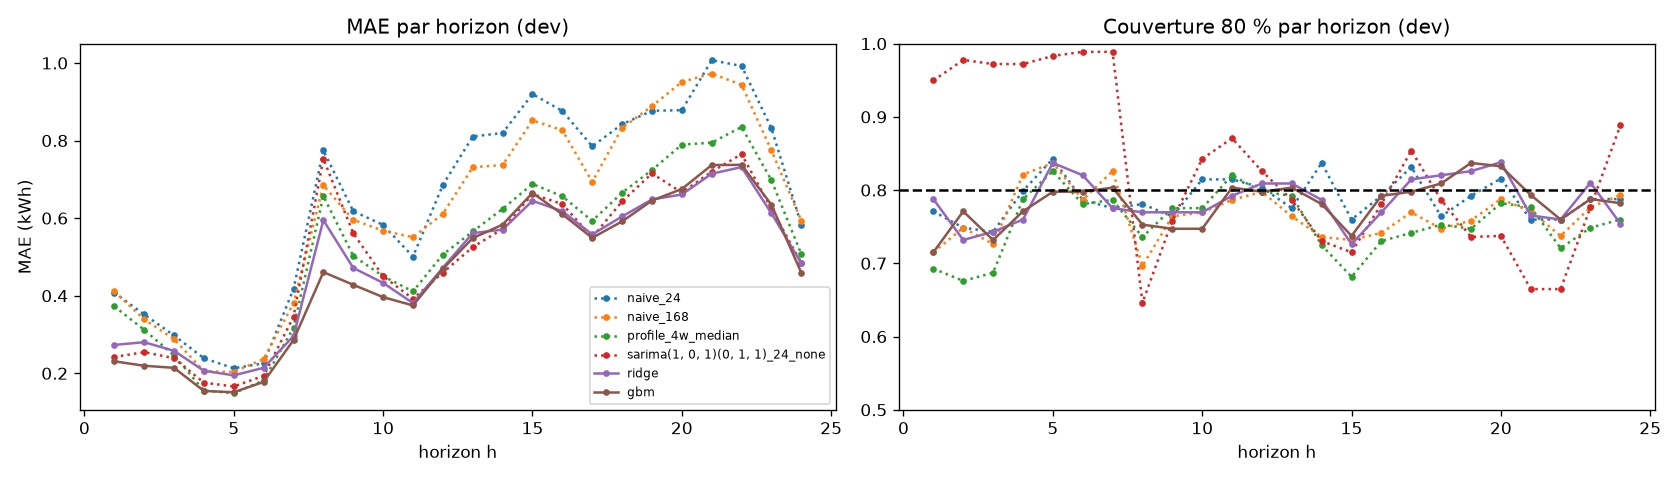

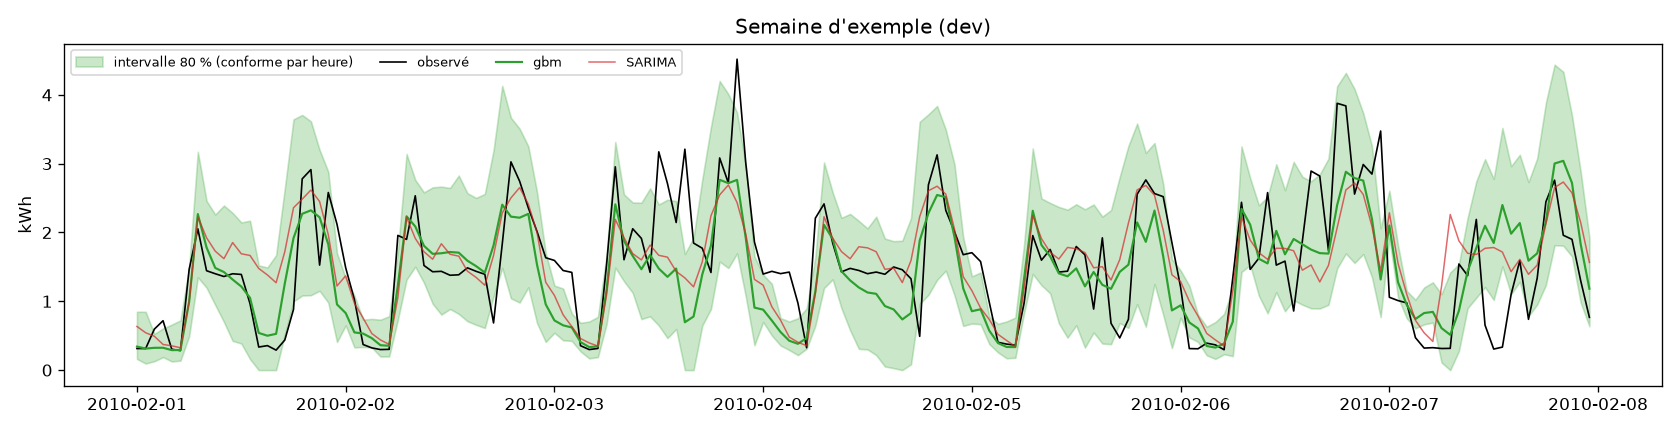

In [3]:
t = pd.DataFrame(r['dev_table']).T
display(t[['MAE','MAE_ci_low','MAE_ci_high','MASE','dMAE_vs_sarima','ci_lo_sarima','ci_hi_sarima','coverage_80','interval_score']].round(4))
fig('05_mae_coverage_by_horizon.png'); fig('05_example_week.png')

## Ablation par groupes et démonstration de fuite

,config,model,n_features,MAE,dMAE_vs_sarima,ci_lo,ci_hi,MAE_h1_3
0,1_lags,ridge,5,0.5156,0.0241,0.0065,0.0406,0.3319
1,1_lags,gbm,5,0.4998,0.0083,-0.0091,0.0253,0.2644
2,2_lags+calendar,ridge,14,0.4873,-0.0042,-0.0154,0.0075,0.2755
3,2_lags+calendar,gbm,14,0.4623,-0.0292,-0.0494,-0.0092,0.2199
4,3_lags+rolling,ridge,11,0.4911,-0.0004,-0.0154,0.0133,0.3081
5,3_lags+rolling,gbm,11,0.4742,-0.0173,-0.0345,-0.0016,0.2615
6,4_lags+rolling+calendar,ridge,20,0.4775,-0.0141,-0.0266,-0.0023,0.2672
7,4_lags+rolling+calendar,gbm,20,0.4572,-0.0344,-0.0560,-0.0141,0.2212
8,5_all,ridge,26,0.4785,-0.0130,-0.0256,-0.0009,0.2704
9,5_all,gbm,26,0.4583,-0.0332,-0.0534,-0.0147,0.2215


fuite : {'MAE_with_leaky_lag_1': 0.34620793520507354, 'MAE_legal_gbm': 0.4583331327027356}


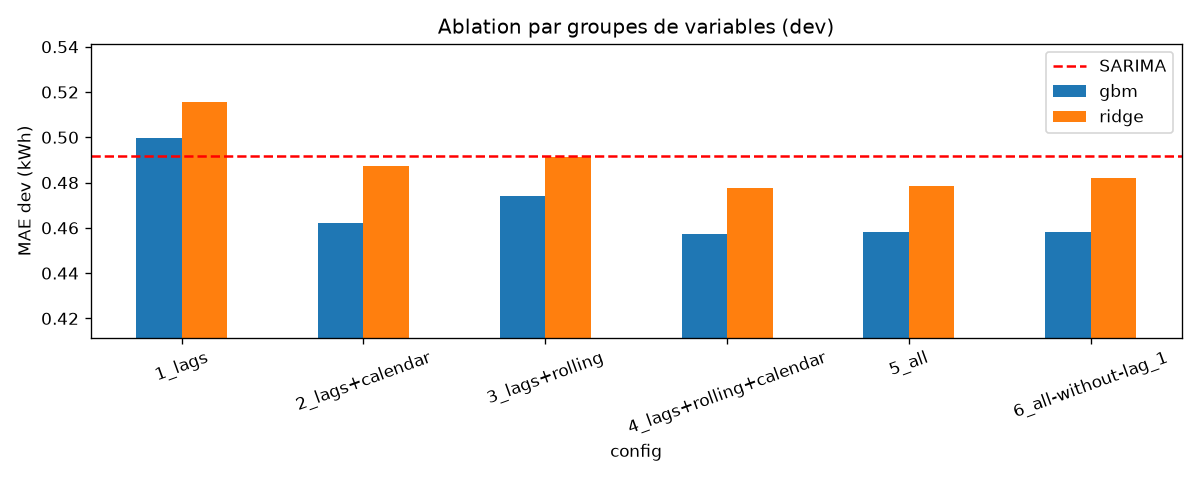

In [4]:
display(pd.DataFrame(r['ablation']).round(4)); print('fuite :', r['leak_demo']); fig('05_ablation.png')

## Revue des 20 variables du modèle retenu (descriptive)

,permutation,drop_MAE,drop_dMAE,drop_ci_lo,drop_ci_hi
lag_1,0.0106,0.4614,0.0035,-0.0021,0.0099
dow_sin,0.0003,0.4612,0.0033,-0.0001,0.0075
doy_cos,0.0046,0.4609,0.0030,-0.0012,0.0072
lag_168,0.0018,0.4605,0.0026,0.0002,0.0051
profile_4w_median,0.0607,0.4604,0.0025,-0.0025,0.0076
lag_336,0.0016,0.4603,0.0025,-0.0012,0.0067
hour_cos,0.0126,0.4592,0.0013,-0.0020,0.0047
same_hour_mean_7d,0.0542,0.4591,0.0012,-0.0050,0.0075
doy_sin,0.0007,0.4584,0.0005,-0.0026,0.0036
lag_48,0.0021,0.4583,0.0004,-0.0029,0.0039


,MAE,dMAE,ci_lo,ci_hi
heure (hour + sin/cos),0.4744,0.0165,0.0077,0.0260
"jour (dayofweek, is_weekend, dow sin/cos)",0.4600,0.0021,-0.0048,0.0088
saison (doy sin/cos),0.4591,0.0013,-0.0032,0.0056
retards 24/48/168/336,0.4612,0.0034,-0.0005,0.0072
profils (same_hour_7d + profile_4w),0.4568,-0.0011,-0.0072,0.0049
"fenêtres de niveau (roll_mean_24/168, std_24)",0.4581,0.0002,-0.0056,0.0075


,MAE,dMAE,ci_lo,ci_hi,n_features
8 variables (une par information),0.4593,0.0014,-0.0045,0.0077,8.0
5 variables,0.4660,0.0081,-0.0007,0.0181,5.0
3 variables (profils + heure),0.4724,0.0145,0.0041,0.0254,3.0


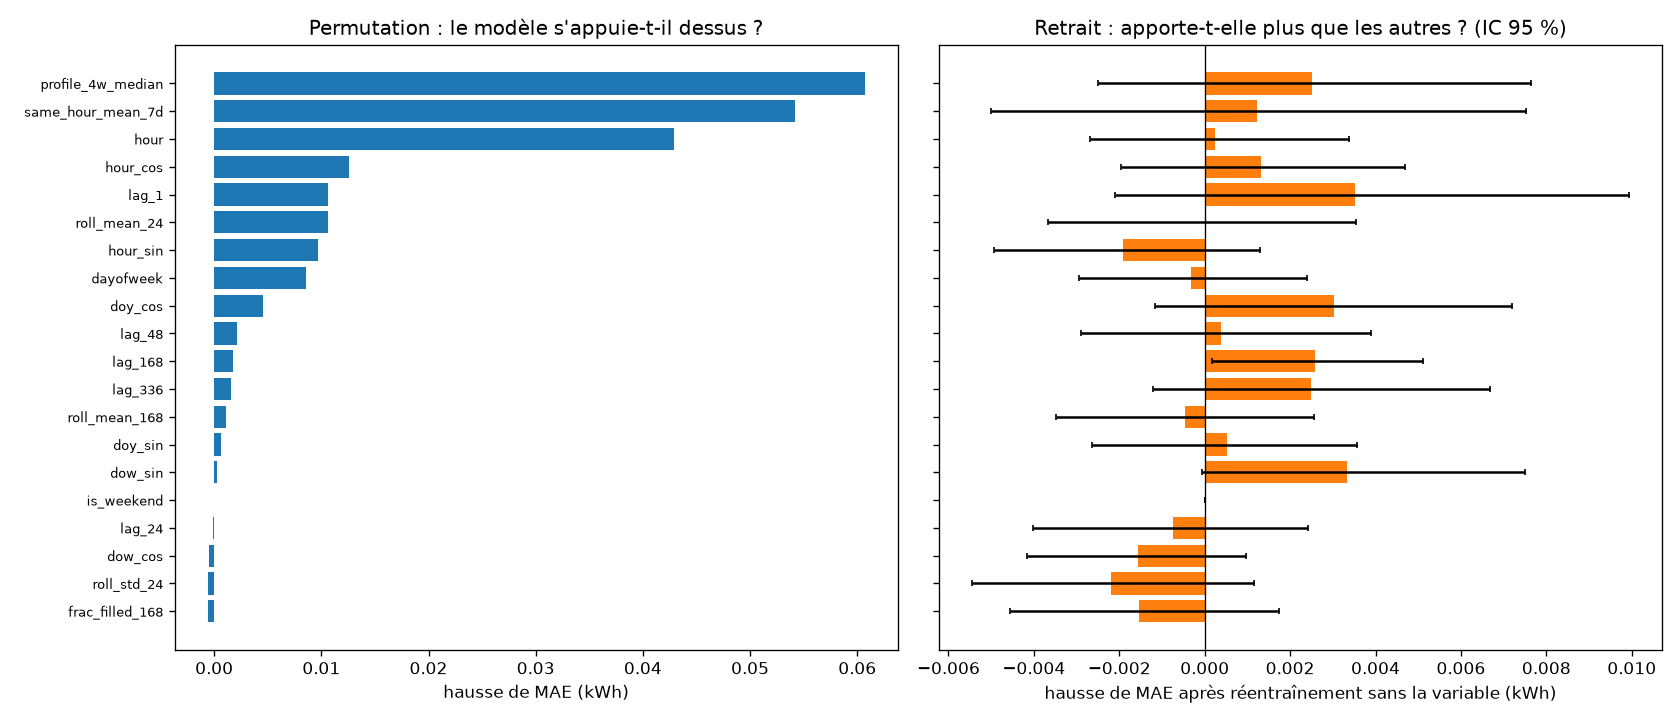

In [5]:
v = load('05b_feature_review.json')
display(pd.DataFrame(v['single']).T.round(4)); display(pd.DataFrame(v['groups']).T.round(4))
display(pd.DataFrame(v['reduced']).T.round(4)); fig('05b_feature_importance.png')